In [58]:
from typing import Annotated, Sequence, TypedDict

from langchain_core.messages import HumanMessage, AIMessage, BaseMessage, ToolMessage, SystemMessage
from langchain_core.tools import tool

from langgraph.graph import StateGraph, END
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode
from langchain_openai import ChatOpenAI

from dotenv import load_dotenv
import os

from litellm import use_chat_completions_url_for_anthropic_messages
from litellm.rust_bridge.ocr.route_host import response
from typer.cli import state

In [59]:
load_dotenv()

API_KEY = os.getenv("API_KEY")
MODEL = os.getenv("MODEL")
BASE_URL = os.getenv("BASE_URL")

In [60]:
# global var to store document content
document_content = ""

In [61]:
class AgentState(TypedDict):
    messages: Annotated[Sequence[BaseMessage], add_messages]

@tool
def update(content: str) -> str:
    """ updates the document with the provided content """
    global document_content
    document_content = content
    return f"Document has been updated. The current content is:\n{document_content}"

@tool
def save(filename: str) -> str:
    """
     Save the current document to a text file and finish the process

     Args:
         filename: Name for the text file
     """

    if not filename.endswith(".txt"):
        filename = f"{filename}.txt"

    global document_content

    try:
        with open(filename, 'w') as file:
            file.write(document_content)
        print(f"\nDocument has been saved to: {filename}")
        return f"Document has been saved successfully to: {filename}"
    except Exception as e:
        return f"Error saving document: {str(e)}"

In [62]:
tools = [save, update]

llm = ChatOpenAI(model=MODEL, api_key=API_KEY, base_url=BASE_URL)
llm = llm.bind_tools(tools)

In [63]:
def our_agent(state: AgentState) -> AgentState:
    system_prompt = SystemMessage(content=f"""
    You are Drafter, a helpful writing assistant. You are going to help the user update and modify documents.

    - If the user wants to update or modify content, use the 'update' tool with the complete updated content.
    - If the user wants to save and finish, you need to use the 'save' tool.
    - Make sure to always show the current document state after modifications.

    The current document content is:{document_content}
    """)

    if not state["messages"]:
        user_input = "I'm ready to help you update a document. What would you like to create?"
        user_message = HumanMessage(content=user_input)
    else:
        user_input = input("\nWhat would you like to do with the document?")
        print(f"\n USER: {user_input}")
        user_message = HumanMessage(content=user_input)

    all_message = [system_prompt] + list(state["messages"]) + [user_message]

    response = llm.invoke(all_message)

    print(f"\n AI: {response.content}")
    if hasattr(response, "tool_calls") and response.tool_calls:
        print(f"\n USING TOOLS: {[tc['name'] for tc in response.tool_calls]}")

    return {"messages": list(state["messages"]) + [user_message, response]}

In [64]:
def should_continue(state: AgentState) -> str:
    """ Determine if we should continue or end the conversation """

    messages = state["messages"]

    if not messages:
        return "continue"

    # This looks for the most recent tool message....
    for message in reversed(messages):
        # ... and checks if this is a ToolMessage resulting from save
        if (isinstance(message, ToolMessage) and
                "saved" in message.content.lower() and
                "document" in message.content.lower()):
            return "end" # goes to the end edge which leads to the endpoint

    return "continue"

def print_messages(messages):
    """ Function to make print more readable format """

    if not messages: return

    for message in messages[-3]:
        if isinstance(message, ToolMessage):
            print(f"\nTOOL RESULT: {message.content}")

In [65]:
OUR_AGENT_NODE = "our_agent"
TOOLS_NODE = "tools"

graph = StateGraph(AgentState)
graph.add_node(OUR_AGENT_NODE, our_agent)
graph.add_node(TOOLS_NODE, ToolNode(tools=tools))

graph.set_entry_point(OUR_AGENT_NODE)
graph.add_edge(OUR_AGENT_NODE, TOOLS_NODE)

graph.add_conditional_edges(
    TOOLS_NODE,
    should_continue,
    {
        "continue": OUR_AGENT_NODE,
        "end": END
    }
)

graph.add_edge(OUR_AGENT_NODE, TOOLS_NODE)

app = graph.compile()

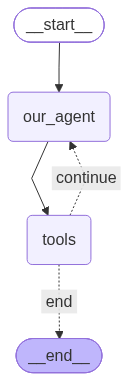

In [66]:
from IPython.display import Image, display
display(Image(app.get_graph().draw_mermaid_png()))

In [67]:
def run_document_agent():
    print("\n====== DRAFTER STARTED ======")

    state = {"messages": []}
    for step in app.stream(state, stream_mode="values"):
        if "messages" in step:
            print_messages(step["messages"])

    print("\n====== DRAFTER FINISHED ======")

if __name__ == "__main__":
    run_document_agent()


====== DRAFTER STARTED ======

 AI: Sure! I'd love to help you create or update a document. To get started, could you let me know:

1. **What type of document** you’re looking for (e.g., a business proposal, a resume, a meeting agenda, a story, a technical spec, etc.)?  
2. **Any specific content or structure** you want included (headings, bullet points, tables, etc.)?  
3. **Any existing text** you’d like me to modify, or should we start from scratch?

Just give me a brief overview, and I’ll draft the document for you.

 USER: write email to bob that i can not attend the meeting

 AI: 

 USING TOOLS: ['update']

TOOL RESULT: Document has been updated. The current content is:
Subject: Unable to Attend Meeting

Hi Bob,

I hope you’re doing well. I’m writing to let you know that I won’t be able to attend tomorrow’s meeting due to a prior commitment. I apologize for any inconvenience this may cause.

Please let me know if there’s anything specific I should catch up on afterward, or if th